In [1]:
import pandas as pd
df=pd.read_csv('.../data/churn.csv')
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '.../data/churn.csv'

In [2]:
import pandas as pd 
import os
print(os.listdir('../data'))
df=pd.read_csv('../data/churn.csv')
df.head()

['churn.csv']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
df.info()

Shape: (7043, 21)

Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-nul

In [4]:
df['Churn'].value_counts()
print("\nChurn %:")
print(df['Churn'].value_counts(normalize=True)*100)


Churn %:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [5]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
df.describe()

Missing values:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicates: 0


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


C:\Users\v and s\AppData\Local\Temp\ipykernel_1872\3416515488.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette='Set2')


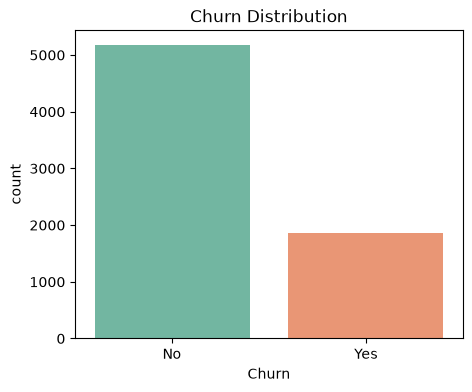

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5,4))
sns.countplot(x='Churn', data=df, palette='Set2')
plt.title('Churn Distribution')
plt.show()

print(df['Churn'].value_counts(normalize=True)*100)

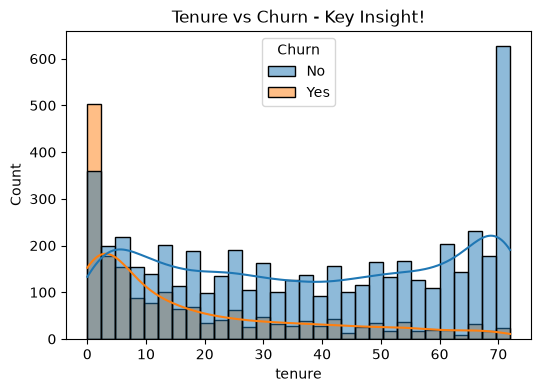

In [7]:
plt.figure(figsize=(6,4))
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, kde=True)
plt.title('Tenure vs Churn - Key Insight!')
plt.show()

In [8]:
print(df['TotalCharges'].head(10))
print(df.dtypes)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [9]:
# Check how many blank spaces
print("Total blank spaces:", (df['TotalCharges'] == ' ').sum())

# Convert to numeric, blanks become NaN
import numpy as np
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])

print("\nAfter fix:")
print(df['TotalCharges'].isnull().sum(), "NaNs")
print(df['TotalCharges'].head())

Total blank spaces: 11

After fix:
11 NaNs
0      29.85
1    1889.50
2     108.15
3    1840.75
4     151.65
Name: TotalCharges, dtype: float64


After fillna, NaNs: 0


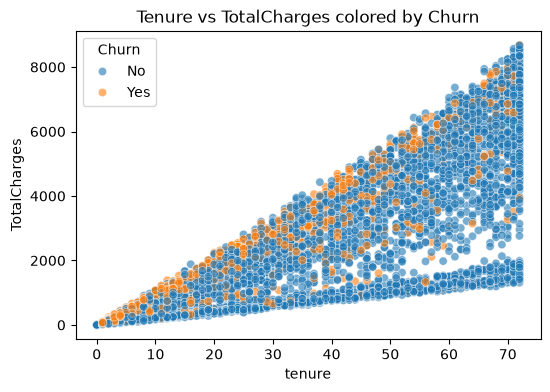

In [10]:
# These 11 customers have 0 tenure, so TotalCharges = 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print("After fillna, NaNs:", df['TotalCharges'].isnull().sum())

# Now plot Monthly vs Total
plt.figure(figsize=(6,4))
sns.scatterplot(x='tenure', y='TotalCharges', hue='Churn', data=df, alpha=0.6)
plt.title('Tenure vs TotalCharges colored by Churn')
plt.show()

In [11]:
# Save cleaned data for Model Training
df.to_csv('../data/churn_cleaned.csv', index=False)
print("Cleaned data saved! Shape:", df.shape)

# Quick interview-ready insights
print("\n--- KEY INSIGHTS FOR RESUME ---")
print(f"Total Customers: {df.shape[0]}")
print(f"Churn Rate: {df['Churn'].value_counts(normalize=True)['Yes']*100:.1f}%")
print(f"Avg tenure churned: {df[df['Churn']=='Yes']['tenure'].mean():.1f} months")
print(f"Avg tenure retained: {df[df['Churn']=='No']['tenure'].mean():.1f} months")

Cleaned data saved! Shape: (7043, 21)

--- KEY INSIGHTS FOR RESUME ---
Total Customers: 7043
Churn Rate: 26.5%
Avg tenure churned: 18.0 months
Avg tenure retained: 37.6 months
